# Nivel 1: Base frente al baseline

¿Cuánto aporta una analítica básica frente a saber solo la edad y el sexo?, y ¿qué modelo lo aprovecha mejor?

| Modelo | Variables | Papel |
|---|---|---|
| Baseline (Cox) | Edad y sexo | Listón a superar |
| Cox | Base (25) | Compite |
| Cox elastic net | Base (25) | Compite |
| Random survival forest | Base (25) | Compite |
| Gradient boosting (XGBoost) | Base (25) | Compite |

Se parte de 25 variables y se termina con 19. Primero con valores fijos y, después, optimizando los mejores. Sin pesos muestrales. Todo con validación cruzada dentro de train: **el test no se toca**.

Notebook de trabajo: importa de `src/`. Tiempo aproximado, si se ejecuta entero: **unos 60 minutos**, casi todos en el bootstrap.

In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.config.model_sets import BASELINE
from src.config.paths import GOLD_TABLE
from src.config.study import COMPARISON_SEED
from src.models.s1_split import cv_folds, split_data
from src.models.s5_evaluation import compare_risks, evaluate_level, plot_calibration, tune_model
from src.utils.notebook_helpers import cox_weights, without

C:\Data\1_MisCosas\Evolve\TFM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Datos

Mismo reparto siempre: 80/20 con 5 bloques dentro de train.

In [2]:
# Base at the start of this notebook; its final version is BASE in model_sets.py
INITIAL_BASE = [
    "age", "sex", "bmi",
    "hemoglobin", "erythrocytes", "mchc", "rdw",
    "neutrophils", "lymphocytes", "monocytes", "eosinophils", "basophils",
    "platelets", "mpv",
    "glucose", "creatinine", "urea", "uric_acid", "total_cholesterol", "hdl", "ast", "alt",
    "sodium", "potassium", "calcium",
]

gold = pd.read_parquet(GOLD_TABLE)
train, test, folds = split_data(gold)

          people       deaths      
part        test train   test train
cycle                              
1999_2000    829  3316    212   846
2001_2002    925  3697    188   750
2003_2004    877  3511    165   661
2005_2006    874  3497    120   479
2007_2008   1043  4170    136   544
2009_2010   1120  4479     99   396
2011_2012    993  3968     70   278
2013_2014   1061  4248     51   206
2015_2016   1011  4043     31   122
2017_2018    966  3867     14    57
train: 38796 people, 4339 deaths
test:  9699 people, 1086 deaths
folds: [7760, 7759, 7759, 7759, 7759] people in each validation part


## 2. Entrenar y evaluar

Cada persona se evalúa con un modelo entrenado sin ella. Tarda unos 15 minutos, casi todos en el random survival forest.

In [3]:
baseline_summary, baseline_details = evaluate_level(BASELINE, train, folds, models=["cox"])
base_summary, base_details = evaluate_level(INITIAL_BASE, train, folds)

## 3. Resumen

| Columna | Qué mide | Mejor |
|---|---|---|
| `c_index` | De dos personas, cuántas veces da más riesgo a la que muere antes en 10 años | Alto |
| `c_index_std` | Cuánto varía entre los 5 bloques | Bajo |
| `c_index_fit` | Lo mismo con personas ya vistas; muy por encima de `c_index` = sobreajuste | Cerca de `c_index` |
| `c_index_same_age` | Lo mismo, dentro de cada grupo de edad: **lo que más importa para el producto** | Alto |
| `c_index_female`, `c_index_male` | Lo mismo, por sexo | Altos y parecidos |
| `calibration_gap` | Diferencia media entre el riesgo previsto y el observado | Bajo |
| `worst_underestimate` | Grupo donde más se queda corto el riesgo previsto; es el error peor | Bajo |
| `seconds_per_fit` | Tiempo de un entrenamiento | Bajo |

In [4]:
summary = pd.concat([baseline_summary.rename(index={"cox": "baseline"}), base_summary])
summary

,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
baseline,0.8159,0.0065,0.8159,0.5983,0.8154,0.8092,0.0046,0.0082,2.8438
cox,0.8477,0.0064,0.8482,0.7031,0.8518,0.8398,0.0040,0.0125,5.1772
elastic_net,0.8473,0.0063,0.8478,0.7030,0.8513,0.8395,0.0049,0.0163,0.9798
random_forest,0.8478,0.0041,0.9342,0.7020,0.8513,0.8403,0.0146,0.0671,99.4946
gradient_boosting,0.8509,0.0053,0.8701,0.7079,0.8543,0.8431,0.0029,0.0044,2.0913


## 4. Por grupo de edad

¿Distingue a personas de la misma edad en todos los grupos? Los grupos con pocas muertes son menos fiables.

In [5]:
by_age = pd.DataFrame({name: detail["by_age"]["c_index"] for name, detail in base_details.items()})
by_age.insert(0, "baseline", baseline_details["cox"]["by_age"]["c_index"])
by_age["deaths"] = baseline_details["cox"]["by_age"]["deaths"].astype(int)
by_age.round(3)

,baseline,cox,elastic_net,random_forest,gradient_boosting,deaths
18-29,0.603,0.676,0.673,0.687,0.705,81
30-39,0.586,0.710,0.710,0.713,0.719,89
40-49,0.584,0.704,0.704,0.704,0.705,217
50-59,0.610,0.736,0.736,0.731,0.741,388
60-69,0.591,0.719,0.719,0.722,0.726,828
70-79,0.603,0.683,0.683,0.680,0.685,1246


## 5. Calibración

Una gráfica por modelo. Sobre la diagonal, el riesgo previsto coincide con el observado; por encima de ella, el modelo se queda corto.

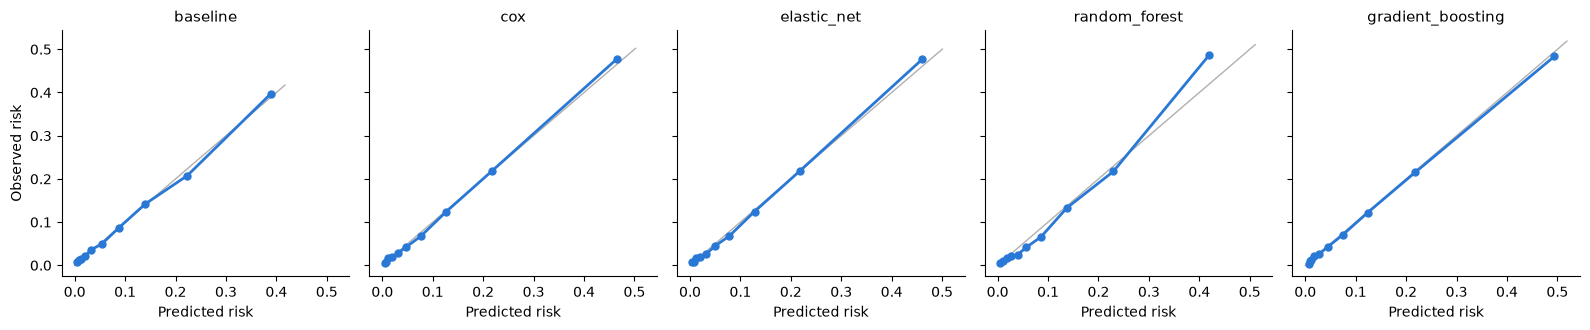

In [6]:
plot_calibration({"baseline": baseline_details["cox"], **base_details});

In [7]:
pd.DataFrame({name: detail["calibration"]["gap"] for name, detail in base_details.items()}).round(3)

,cox,elastic_net,random_forest,gradient_boosting
0,0.002,0.002,0.002,-0.002
1,-0.001,-0.001,-0.002,0.001
2,0.005,0.004,-0.003,0.000
3,-0.000,-0.001,-0.006,0.004
4,-0.003,-0.006,-0.015,-0.001
5,-0.005,-0.005,-0.015,-0.002
6,-0.009,-0.010,-0.020,-0.004
7,-0.003,-0.004,-0.004,-0.002
8,0.001,0.001,-0.012,-0.003
9,0.012,0.016,0.067,-0.010


## 6. ¿La analítica aporta de verdad?

Comparación con bootstrap de Cox frente al baseline, de unos 22 minutos. La mejora es real si el intervalo (`low`, `high`) no incluye el 0.

In [4]:
# Cox against the baseline
compare_risks(base_details["cox"]["risk"], baseline_details["cox"]["risk"], train)

,difference,low,high
c_index,0.0319,0.0285,0.0348
c_index_same_age,0.1052,0.0944,0.1159


## 7. Modelos que pasan a optimizarse: Cox y XGBoost

Con valores fijos, de cada 100 parejas de personas de edad parecida, XGBoost ordena bien solo media más que Cox. A efectos prácticos, son iguales.

- **XGBoost:** mejor C-index global y por misma edad, mejor calibración y menor infraestimación.
- **Cox:** casi igual de preciso, sin sobreajuste y el más sencillo de explicar.
- **Random survival forest:** descartado por su fuerte sobreajuste y porque se queda corto en el grupo de mayor riesgo.
- **Elastic net:** igual que Cox con valores fijos. Pasa como la versión de Cox que se puede optimizar, porque Cox simple no tiene ajustes.

Se optimizan XGBoost y elastic net, y se comparan con Cox simple en C-index misma edad, con bloques distintos a los usados para optimizar.

## 8. Optimizar

50 intentos por modelo, buscando el mejor C-index misma edad en los mismos bloques de antes. Tarda unos 45 minutos.

In [3]:
tuned = {name: tune_model(name, INITIAL_BASE, train, folds) for name in ["gradient_boosting", "elastic_net"]}
tuned

{'gradient_boosting': {'n_estimators': 655,
  'learning_rate': 0.056252020354195395,
  'max_depth': 2,
  'min_child_weight': 24,
  'subsample': 0.8863972904161392,
  'colsample_bytree': 0.9960849465698883,
  'reg_lambda': 0.0026276981261043556},
 'elastic_net': {'alphas': [0.0001434715951720141],
  'l1_ratio': 0.8675143843171859}}

## 9. Comparar

Con bloques nuevos, para que la optimización no infle el resultado.

In [4]:
comparison_folds = cv_folds(train, seed=COMPARISON_SEED)
tuned_summary, tuned_details = evaluate_level(INITIAL_BASE, train, comparison_folds, models=["cox", "elastic_net", "gradient_boosting"], settings=tuned)
tuned_summary

,c_index,c_index_std,c_index_fit,c_index_same_age,c_index_female,c_index_male,calibration_gap,worst_underestimate,seconds_per_fit
cox,0.8474,0.0026,0.8483,0.7018,0.8512,0.8395,0.0041,0.0126,5.1862
elastic_net,0.8473,0.0026,0.8482,0.7018,0.8511,0.8394,0.0043,0.0128,1.0143
gradient_boosting,0.8534,0.0022,0.8690,0.7149,0.8567,0.8456,0.0049,0.0106,4.5981


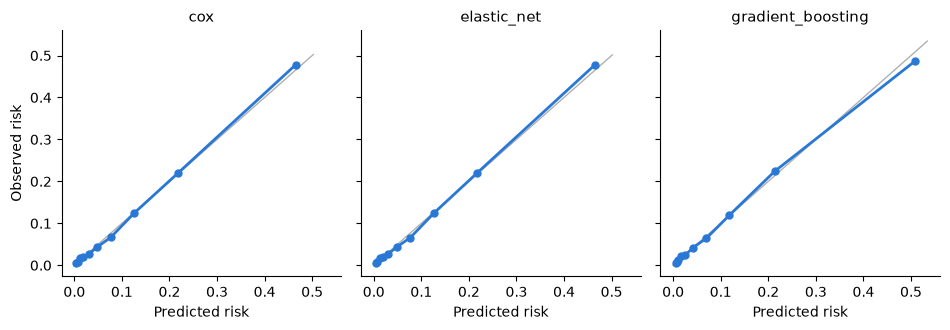

In [5]:
plot_calibration(tuned_details);

## 10. Peso de cada variable en Cox

Cox simple ajustado con todo train, sin validación: describe el modelo, no mide su acierto.

- **`hazard_ratio`:** por cuánto se multiplica el riesgo al subir la variable una desviación estándar, a igualdad de las demás. Por encima de 1, suma riesgo; por debajo, resta. Al estar escaladas, se pueden comparar entre sí.
- **`low`, `high`:** su intervalo de confianza del 95 %. Si incluye el 1, el efecto no se distingue de cero (`clear` = False).

Son 26 columnas porque el IMC tiene también su término al cuadrado. Una variable sin efecto claro aquí puede aportarlo a través de otra muy relacionada con ella, así que esta tabla orienta, pero no decide sola.

In [3]:
weights = cox_weights(INITIAL_BASE, train)
weights.sort_values("p").round(3)

,hazard_ratio,low,high,p,clear
covariate,,,,,
age,3.420,3.261,3.588,0.000,True
rdw,1.316,1.276,1.356,0.000,True
erythrocytes,0.676,0.636,0.718,0.000,True
glucose,1.181,1.151,1.212,0.000,True
ast,1.313,1.252,1.377,0.000,True
alt,0.738,0.697,0.781,0.000,True
hemoglobin,1.355,1.269,1.446,0.000,True
neutrophils,1.170,1.129,1.213,0.000,True
creatinine,1.111,1.083,1.140,0.000,True


## 11. Variantes de Base

Mismo Cox y mismos bloques, cambiando solo las variables. Una variante vale si baja como mucho **0,002** el C-index misma edad frente a las 25 actuales.

| Variante | Qué cambia |
|---|---|
| `all_25` | Base actual |
| `a_no_unclear` | Quita las 6 variables sin efecto claro |
| `a_keep_platelets` | Igual, pero deja las plaquetas, cuyo efecto podría ser en U |
| `b_one_red_cell` | Igual que `a_no_unclear` y, además, sin hematíes ni CHCM, para ver si se corrige el signo de la hemoglobina |

In [3]:
UNCLEAR = ["platelets", "calcium", "mpv", "basophils", "total_cholesterol", "eosinophils"]

variants = {
    "all_25": INITIAL_BASE,
    "a_no_unclear": without(INITIAL_BASE, UNCLEAR),
    "a_keep_platelets": without(INITIAL_BASE, without(UNCLEAR, ["platelets"])),
    "b_one_red_cell": without(INITIAL_BASE, UNCLEAR + ["erythrocytes", "mchc"]),
}
variant_summary = pd.concat(
    {name: evaluate_level(columns, train, folds, models=["cox"])[0].iloc[0] for name, columns in variants.items()}, axis=1
).T
variant_summary.insert(0, "variables", [len(columns) for columns in variants.values()])
variant_summary["same_age_change"] = variant_summary["c_index_same_age"] - variant_summary.loc["all_25", "c_index_same_age"]
variant_summary[["variables", "c_index", "c_index_same_age", "same_age_change", "calibration_gap", "worst_underestimate"]]

,variables,c_index,c_index_same_age,same_age_change,calibration_gap,worst_underestimate
all_25,25,0.8477,0.7031,0.0000,0.0040,0.0125
a_no_unclear,19,0.8476,0.7034,0.0003,0.0042,0.0139
a_keep_platelets,20,0.8476,0.7033,0.0002,0.0042,0.0125
b_one_red_cell,17,0.8438,0.6952,-0.0079,0.0034,0.0102


In [4]:
cox_weights(variants["b_one_red_cell"], train)[["hazard_ratio", "low", "high"]].sort_values("hazard_ratio", ascending=False).round(3)

,hazard_ratio,low,high
covariate,,,
age,3.626,3.461,3.798
ast,1.375,1.311,1.442
sex_male,1.365,1.261,1.478
rdw,1.232,1.199,1.267
glucose,1.170,1.141,1.201
neutrophils,1.162,1.122,1.203
creatinine,1.139,1.110,1.169
uric_acid,1.113,1.077,1.150
potassium,1.086,1.057,1.117


## 12. Conclusión

**Modelo del nivel 1: Cox simple con 19 variables.** Las cifras son de validación cruzada dentro de train; el test sigue sin tocar.

### Qué se hizo y por qué

**1. Comparar los cuatro modelos con valores fijos y las 25 variables iniciales**

| Modelo | C-index | Misma edad | En entrenamiento |
|---|---|---|---|
| Baseline (edad y sexo) | 0,816 | 0,598 | 0,816 |
| Cox | 0,848 | 0,703 | 0,848 |
| Elastic net | 0,847 | 0,703 | 0,848 |
| Random survival forest | 0,848 | 0,702 | 0,934 |
| XGBoost | 0,851 | 0,708 | 0,870 |

Todos superan con claridad al baseline. La columna que mide lo que aporta el producto es la de misma edad, porque la edad sola ya ordena muy bien a la población general.

**2. Descartar lo que no merecía seguir**

- **Random survival forest:** fuerte sobreajuste (0,934 en entrenamiento y 0,848 fuera) y 6,7 puntos de infraestimación en el grupo de mayor riesgo, el error que más queremos evitar. Es además el más lento y el que más ocupa.
- **Cox y XGBoost pasan:** con valores fijos, XGBoost solo ordena bien media pareja más de cada 100 de edad parecida, así que a efectos prácticos son iguales.
- **Elastic net pasa como la versión de Cox que se puede optimizar,** porque Cox simple no tiene ajustes.

**3. Optimizar XGBoost y elastic net con 50 intentos, y comparar con otros bloques**

| Modelo | C-index | Misma edad | En entrenamiento | Mayor infraestimación |
|---|---|---|---|---|
| Cox simple | 0,847 | 0,702 | 0,848 | 1,3 puntos |
| Elastic net optimizado | 0,847 | 0,702 | 0,848 | 1,3 puntos |
| XGBoost optimizado | 0,853 | 0,715 | 0,869 | 1,1 puntos |

- **Elastic net** no aporta nada: su penalización óptima es casi nula y equivale a Cox.
- **XGBoost** ordena bien 1,3 parejas más de cada 100 de edad parecida, con algo más de sobreajuste.

**4. Elegir Cox simple**

No compensa perder la explicabilidad por clasificar mejor 1 de cada 100. El producto tiene que decir qué parámetros suman y cuáles restan, y en Cox cada variable tiene un único peso, igual para todas las personas. Además, no muestra sobreajuste.

**5. Confirmar que la analítica aporta de verdad**

Cox frente al baseline, con bootstrap: **+0,032** de C-index global (intervalo del 95 %: 0,029 a 0,035) y **+0,105** en misma edad (0,094 a 0,116). Como los intervalos no incluyen el 0, la mejora es real: unas 10 parejas más de cada 100 entre personas de edad parecida.

**6. Quitar las variables que no aportan**

La tabla de pesos mostró 6 variables sin efecto claro: plaquetas, VPM, eosinófilos, basófilos, colesterol total y calcio. Al quitarlas, el C-index misma edad no baja (0,7031 → 0,7034). Se quitan: son menos datos que puedan faltarle al usuario.

**7. Probar a dejar una sola variable de la serie roja**

La hemoglobina aparecía sumando riesgo, porque va muy ligada a los hematíes y a la CHCM. Quitar estas dos corrige su signo, pero baja el C-index misma edad en 0,008 y no arregla otros signos. No compensa.

### Resultado final

| Cox simple, 19 variables | |
|---|---|
| C-index | 0,848 |
| C-index misma edad | 0,703 |
| Diferencia media de calibración | 0,4 puntos |
| Mayor infraestimación | 1,4 puntos |

**Variables:** edad, sexo, IMC, hemoglobina, hematíes, CHCM, RDW, neutrófilos, linfocitos, monocitos, glucosa, creatinina, urea, ácido úrico, HDL, AST, ALT, sodio y potasio.

### Limitaciones

- **Signos difíciles de leer:** hemoglobina, ALT y urea tienen un peso contrario al esperado, porque cada peso se lee "manteniendo iguales las demás". Para explicarlo, habrá que agrupar las variables ligadas, como la serie roja o las transaminasas. La urea sigue sin solución.
- **RDW:** su escala cambió con el analizador en 2013, según la CDC. Falta medir cuánto mueve la edad biológica.
- **Colesterol total:** no se usa, aunque el usuario lo buscará en su analítica. La app tendrá que aclararlo.
- **Sin pesos muestrales** y con población de EE. UU.; se asume equivalencia con España.
- **Falta el test,** que se mira una sola vez, al final.